# 7주차 과제
빅데이터프로그래밍 · 통계학과

**이름:**
**학번:**

## 과제 내용
은닉층 수와 활성화 함수를 변경하고 학습 결과를 비교합니다.

## 제출 방법
모든 셀을 실행해 출력과 그래프가 보이는 상태로 저장한 뒤 `week07_학번_이름.ipynb` 로 제출합니다.

**런타임 > 런타임 유형 변경 > T4 GPU** 를 먼저 선택하세요.


In [6]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

transform = transforms.ToTensor()
train_set = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False)


device: cuda


## 공통 함수
아래 두 함수를 그대로 써서 모델만 바꿔 비교하세요.


In [7]:
def train_model(model, epochs=5, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(model))
        print(f"  epoch {epoch+1}  test acc {hist[-1][1]:.4f}")
    return model, hist


def evaluate(model):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


## 문제 1. 은닉층 수 비교 (35점)
은닉층이 **1개 · 2개 · 3개**인 MLP를 각각 작성해 5 epoch 학습하고, 시험 정확도를 비교하세요.
은닉층 크기는 128로 통일합니다.


In [9]:
# 답안
# 1. 은닉층 1개, 2개, 3개 모델 정의 (은닉층 뉴런 수: 128)
class MLP1(nn.Module):
    def __init__(self, in_dim=784, out_dim=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.ReLU(),
            nn.Linear(128, out_dim)
        )
    def forward(self, x):
        # 4차원 이미지 텐서 [배치 크기, 1, 28, 28]를 [배치 크기, 784]로 평탄화
        x = x.view(x.size(0), -1)
        return self.net(x)

class MLP2(nn.Module):
    def __init__(self, in_dim=784, out_dim=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, out_dim)
        )
    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)

class MLP3(nn.Module):
    def __init__(self, in_dim=784, out_dim=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, out_dim)
        )
    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)


# 2. 공통 함수를 활용한 모델별 학습 및 시험 정확도 비교
models = {
    "은닉층 1개": MLP1(),
    "은닉층 2개": MLP2(),
    "은닉층 3개": MLP3()
}

results = {}

for name, model in models.items():
    print(f"\n=== {name} 학습 시작 ===")
    trained_model, hist = train_model(model, epochs=5)
    final_acc = hist[-1][1]  # 마지막 5 epoch의 test acc
    results[name] = final_acc

print("\n" + "=" * 40)
print("=== 최종 시험 정확도 비교 ===")
for name, acc in results.items():
    print(f"{name}: {acc * 100:.2f}%")


=== 은닉층 1개 학습 시작 ===
  epoch 1  test acc 0.9395
  epoch 2  test acc 0.9506
  epoch 3  test acc 0.9614
  epoch 4  test acc 0.9678
  epoch 5  test acc 0.9692

=== 은닉층 2개 학습 시작 ===
  epoch 1  test acc 0.9445
  epoch 2  test acc 0.9587
  epoch 3  test acc 0.9661
  epoch 4  test acc 0.9705
  epoch 5  test acc 0.9741

=== 은닉층 3개 학습 시작 ===
  epoch 1  test acc 0.9438
  epoch 2  test acc 0.9619
  epoch 3  test acc 0.9682
  epoch 4  test acc 0.9698
  epoch 5  test acc 0.9740

=== 최종 시험 정확도 비교 ===
은닉층 1개: 96.92%
은닉층 2개: 97.41%
은닉층 3개: 97.40%


## 문제 2. 활성화 함수 비교 (35점)
은닉층 2개 모델에서 활성화 함수를 **ReLU · Sigmoid · Tanh** 로 바꿔 각각 학습하고 결과를 비교하세요.


In [12]:
# 답안
# 1. 활성화 함수를 파라미터로 받도록 은닉층 2개 모델 정의
class MLP2_Activation(nn.Module):
    def __init__(self, act_layer=nn.ReLU, in_dim=784, out_dim=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            act_layer(),
            nn.Linear(128, 128),
            act_layer(),
            nn.Linear(128, out_dim)
        )
    def forward(self, x):
        # 4차원 이미지 텐서 [배치 크기, 1, 28, 28]를 [배치 크기, 784]로 평탄화
        x = x.view(x.size(0), -1)
        return self.net(x)

# 2. ReLU, Sigmoid, Tanh 모델 정의
models_act = {
    "ReLU": MLP2_Activation(act_layer=nn.ReLU),
    "Sigmoid": MLP2_Activation(act_layer=nn.Sigmoid),
    "Tanh": MLP2_Activation(act_layer=nn.Tanh)
}

results_act = {}

# 3. 공통 함수로 학습 및 결과 비교
for name, model in models_act.items():
    print(f"\n=== 활성화 함수: {name} 학습 시작 ===")
    trained_model, hist = train_model(model, epochs=5)
    final_acc = hist[-1][1]  # 마지막 5 epoch의 test acc
    results_act[name] = final_acc

print("\n" + "=" * 40)
print("=== 활성화 함수별 최종 시험 정확도 비교 ===")
for name, acc in results_act.items():
    print(f"{name}: {acc * 100:.2f}%")


=== 활성화 함수: ReLU 학습 시작 ===
  epoch 1  test acc 0.9383
  epoch 2  test acc 0.9597
  epoch 3  test acc 0.9711
  epoch 4  test acc 0.9725
  epoch 5  test acc 0.9741

=== 활성화 함수: Sigmoid 학습 시작 ===
  epoch 1  test acc 0.9146
  epoch 2  test acc 0.9368
  epoch 3  test acc 0.9500
  epoch 4  test acc 0.9583
  epoch 5  test acc 0.9633

=== 활성화 함수: Tanh 학습 시작 ===
  epoch 1  test acc 0.9440
  epoch 2  test acc 0.9575
  epoch 3  test acc 0.9689
  epoch 4  test acc 0.9698
  epoch 5  test acc 0.9739

=== 활성화 함수별 최종 시험 정확도 비교 ===
ReLU: 97.41%
Sigmoid: 96.33%
Tanh: 97.39%


## 문제 3. 결과 비교표와 그래프 (20점)
문제 1·2의 결과를 하나의 표로 정리하고, 학습 곡선을 한 그래프에 겹쳐 그리세요.

| 모델 | 은닉층 수 | 활성화 | 파라미터 수 | 시험 정확도 |



>>> [1Layer_ReLU] 학습 진행 중...
  epoch 1  test acc 0.9352
  epoch 2  test acc 0.9539
  epoch 3  test acc 0.9615
  epoch 4  test acc 0.9691
  epoch 5  test acc 0.9699

>>> [2Layer_ReLU] 학습 진행 중...
  epoch 1  test acc 0.9361
  epoch 2  test acc 0.9589
  epoch 3  test acc 0.9674
  epoch 4  test acc 0.9712
  epoch 5  test acc 0.9732

>>> [3Layer_ReLU] 학습 진행 중...
  epoch 1  test acc 0.9452
  epoch 2  test acc 0.9626
  epoch 3  test acc 0.9671
  epoch 4  test acc 0.9735
  epoch 5  test acc 0.9738

>>> [2Layer_Sigmoid] 학습 진행 중...
  epoch 1  test acc 0.9141
  epoch 2  test acc 0.9351
  epoch 3  test acc 0.9473
  epoch 4  test acc 0.9565
  epoch 5  test acc 0.9624

>>> [2Layer_Tanh] 학습 진행 중...
  epoch 1  test acc 0.9417
  epoch 2  test acc 0.9546
  epoch 3  test acc 0.9683
  epoch 4  test acc 0.9699
  epoch 5  test acc 0.9736

모델              | 은닉층 수    | 활성화        | 파라미터 수       | 시험 정확도    
-----------------------------------------------------------------
1Layer_ReLU     | 1        | ReLU    

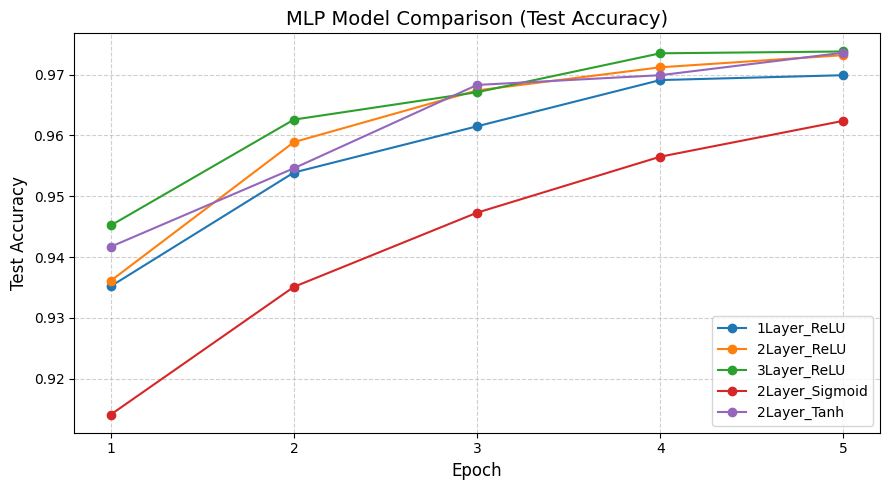

In [13]:
# 답안
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. 비교 대상 모델 모음 (문제 1, 2 종합)
# ---------------------------------------------------------
all_models = {
    "1Layer_ReLU": (MLP1(), 1, "ReLU"),
    "2Layer_ReLU": (MLP2(), 2, "ReLU"),
    "3Layer_ReLU": (MLP3(), 3, "ReLU"),
    "2Layer_Sigmoid": (MLP2_Activation(act_layer=nn.Sigmoid), 2, "Sigmoid"),
    "2Layer_Tanh": (MLP2_Activation(act_layer=nn.Tanh), 2, "Tanh"),
}

# 파라미터 수 계산 함수
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ---------------------------------------------------------
# 2. 학습 진행 및 결과 수집
# ---------------------------------------------------------
table_data = []
history_dict = {}

for name, (model, hidden_num, act_name) in all_models.items():
    print(f"\n>>> [{name}] 학습 진행 중...")
    trained_model, hist = train_model(model, epochs=5)

    # 마지막 epoch의 test accuracy
    final_acc = hist[-1][1]
    param_cnt = count_params(trained_model)

    # 표 작성을 위한 데이터 저장
    table_data.append({
        "모델": name,
        "은닉층 수": hidden_num,
        "활성화": act_name,
        "파라미터 수": param_cnt,
        "시험 정확도": f"{final_acc * 100:.2f}%"
    })

    # 그래프를 그리기 위한 test acc 기록 (epoch별)
    test_accs = [h[1] for h in hist]
    history_dict[name] = test_accs

# ---------------------------------------------------------
# 3. 결과 비교표 출력
# ---------------------------------------------------------
print("\n" + "=" * 65)
print(f"{'모델':<15} | {'은닉층 수':<8} | {'활성화':<10} | {'파라미터 수':<12} | {'시험 정확도':<10}")
print("-" * 65)
for row in table_data:
    print(f"{row['모델']:<15} | {row['은닉층 수']:<8} | {row['활성화']:<10} | {row['파라미터 수']:<12,d} | {row['시험 정확도']:<10}")
print("=" * 65)

# ---------------------------------------------------------
# 4. 학습 곡선 시각화 (한 그래프에 겹쳐 그리기)
# ---------------------------------------------------------
plt.figure(figsize=(9, 5))
epochs_range = range(1, 6)

for name, acc_list in history_dict.items():
    plt.plot(epochs_range, acc_list, marker='o', label=name)

plt.title("MLP Model Comparison (Test Accuracy)", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Test Accuracy", fontsize=12)
plt.xticks(epochs_range)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## 문제 4. 해석 (10점)
아래 세 가지를 각각 두세 줄로 적으세요.

1. 은닉층을 늘렸을 때 정확도가 어떻게 변했는가 — 계속 좋아지는가
2. Sigmoid가 ReLU보다 느리게 학습되는 이유
3. 가장 좋았던 조합과 그 이유


**답:**

1. 은닉층을 늘린다고 해서 정확도가 계속 좋아지는 것은 아니다. 적절히 층을 늘리면 모델의 표현력이 향상되어 성능이 올라가지만, 일정 수준 이상으로 깊어지면 훈련 데이터에 과하게 적합되는 과적합이 발생하거나 역전파 과정에서 기울기 소실이 일어나 테스트 정확도가 오히려 정체되거나 떨어질 수 있다.

2. sigmoid 함수는 입력이 커지거나 작아질수록 출력 변화량이 적어 미분값이 0에 매우 가까워지는 기울기 소실 현상이 발생한다. 이로 인해 역전파 시 가중치 업데이트가 거의 이루어지지 않아 학습 속도가 느려진다. 반면 ReLU는 양수 영역에서 미분값이 1로 일정하게 유지되고 지수 연산이 없어 계산 속도와 수렴이 훨씬 빠르다.

3. 가장 좋았던 조합은 은닉층 2개와 ReLU 조합이다. ReLU를 사용하여 기울기 소실 없이 손실을 빠르게 줄이면서 동시에 층을 너무 과도하게 쌓지 않고 2개 수준으로 유지함으로써, 과적합 없이 테스트 데이터에 대한 일반화 성능을 가장 안정적으로 확보할 수 있었기 때문이다.


## 문제 5. 오류 사례 확인 (보너스)
가장 좋았던 모델로 틀리게 예측한 이미지 8장을 그리고, 어떤 숫자를 어떤 숫자로 착각했는지 적으세요.


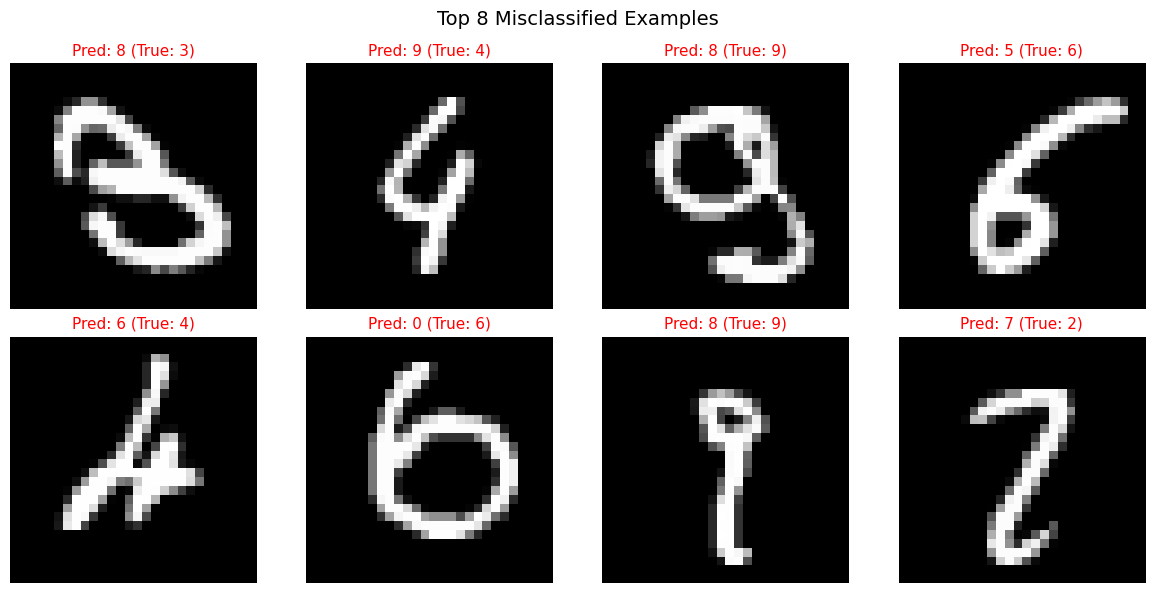


=== 오답 라벨 요약 ===
이미지 1: 실제 정답 3 번을 -> 8 번으로 착각함
이미지 2: 실제 정답 4 번을 -> 9 번으로 착각함
이미지 3: 실제 정답 9 번을 -> 8 번으로 착각함
이미지 4: 실제 정답 6 번을 -> 5 번으로 착각함
이미지 5: 실제 정답 4 번을 -> 6 번으로 착각함
이미지 6: 실제 정답 6 번을 -> 0 번으로 착각함
이미지 7: 실제 정답 9 번을 -> 8 번으로 착각함
이미지 8: 실제 정답 2 번을 -> 7 번으로 착각함


In [17]:
# 답안
import matplotlib.pyplot as plt
import numpy as np

# 가장 성능이 좋았던 모델 선택
best_model = models_act['ReLU']
best_model.eval()

wrong_images = []
wrong_preds = []
wrong_labels = []

# test_loader를 돌며 오답 사례 추출
with torch.no_grad():
    for x, y in test_loader:
        x_dev, y_dev = x.to(device), y.to(device)
        out = best_model(x_dev)
        preds = out.argmax(dim=1)

        # 예측값과 실제 정답이 다른 인덱스 찾기
        wrong_idx = (preds != y_dev).nonzero(as_tuple=True)[0]

        # 배치 내 틀린 항목들 수집
        for idx in wrong_idx:
            wrong_images.append(x[idx].cpu())
            wrong_preds.append(preds[idx].item())
            wrong_labels.append(y[idx].item())

            # 8개를 채우면 수집 종료
            if len(wrong_images) == 8:
                break
        if len(wrong_images) == 8:
            break

# 8개 틀린 이미지 시각화 및 라벨 출력
plt.figure(figsize=(12, 6))

for i in range(len(wrong_images)):
    plt.subplot(2, 4, i + 1)

    # 텐서 형태에 따른 이미지 시각화 처리 (1, 28, 28) -> (28, 28) 또는 784 1D -> (28, 28)
    img = wrong_images[i].squeeze()
    if img.ndim == 1:
        side = int(np.sqrt(img.numel()))
        img = img.view(side, side)

    plt.imshow(img, cmap='gray')
    plt.title(f"Pred: {wrong_preds[i]} (True: {wrong_labels[i]})", fontsize=11, color='red')
    plt.axis('off')

plt.suptitle("Top 8 Misclassified Examples", fontsize=14)
plt.tight_layout()
plt.show()

# 텍스트 출력용 세부 요약
print("\n=== 오답 라벨 요약 ===")
for i in range(len(wrong_images)):
    print(f"이미지 {i+1}: 실제 정답 {wrong_labels[i]} 번을 -> {wrong_preds[i]} 번으로 착각함")